# Plasma protein abundance during rGH treatment and washout

**Research question:** How do selected plasma protein abundance ratios change during recombinant human growth hormone (rGH) treatment and subsequent washout?

I am looking at six proteins: Afamin, APOL1, ECM1, IGFBP3, ALS, and Lumican.

## 1. Data source

The data are from Tan et al. (2017), *Plasma biomarker proteins for detection of human growth hormone administration in athletes*.

- Article: https://doi.org/10.1038/s41598-017-09968-7
- Dataset: Supplementary Data 2, Excel workbook
- Access date: November 8, 2026

I used the worksheet **Combined 6 iTRAQ runs**. The Excel file is saved in the `data/` folder and is loaded using a relative path.

## 2. Loading and understanding the data

The worksheet contains results from six iTRAQ runs. Each measurement group has a ratio, p-value, error factor, and lower and upper confidence limits. I first checked the worksheet headers and the experimental design to understand how the columns were organized.

In [1]:
import sys
import pandas as pd
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pathlib import Path

file_path = Path("data/41598_2017_9968_MOESM2_ESM.xls")

# Read the original headers and the data table.
headers = pd.read_excel(
    file_path,
    sheet_name="Combined 6 iTRAQ runs",
    header=None,
    nrows=8
)

data = pd.read_excel(
    file_path,
    sheet_name="Combined 6 iTRAQ runs",
    header=7
)

design = pd.read_excel(
    file_path,
    sheet_name="iTRAQ Experimental Design",
    header=None
)

print("Data shape:", data.shape)
display(headers.iloc[5:8, 9:14])
display(design)

Data shape: (385, 99)


,9,10,11,12,13
5,NaN,NaN,NaN,NaN,NaN
6,Ratio,P-value,Error factor,Lower CI,Upper CI
7,Run 1 NTTP0/TTP0,NaN,NaN,NaN,NaN


,0,1,2,3,4
0,Supplemental Data_2:,NaN,NaN,NaN,NaN
1,"Title: ""Plasma biomarker proteins for detectio...",NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN
3,iTRAQ MS/MS experimental design,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN
5,iTRAQ 4-plex experiement,114,115,116,117
6,iTRAQ Run1,NTTP0,TTP0,NTTP1,TTP1
7,iTRAQ Run2,NTTP2,TTP0,TTP2,TTP1
8,iTRAQ Run3,NTTP3,TTP3,TTP0,TTP3
9,iTRAQ Run4,NTTP4,TTP4,TTP4,TTP0


### Experimental design

The time points used here are TTP0 (baseline), TTP1 (treatment week 4), TTP2 (treatment week 8), TTP3 (washout day 1), TTP4 (washout day 2), TTP5 (washout day 4), and TTP6 (washout week 6).

TTP0 is the reference used to calculate the abundance ratios. A ratio of 1 means no change from this baseline. The ratios are dimensionless.

Each sample was pooled from eight participants. Therefore, one row in my analysis represents an analytical channel/run measurement, not one participant.

## 3. Data processing

I made a map of the columns for each time point. Each measurement group has five columns: ratio, p-value, error factor, lower confidence interval, and upper confidence interval. There are 11 measurement channels in total.

In [2]:
measurement_map = pd.DataFrame({
    "Time point": [
        "TTP1", "TTP1", "TTP2", "TTP2",
        "TTP3", "TTP3", "TTP4", "TTP4",
        "TTP5", "TTP5", "TTP6"
    ],
    "Collection time": [
        "Week 4", "Week 4", "Week 8", "Week 8",
        "Washout day 1", "Washout day 1",
        "Washout day 2", "Washout day 2",
        "Washout day 4", "Washout day 4",
        "Washout week 6"
    ],
    "Run": [1, 2, 2, 6, 3, 3, 4, 4, 5, 6, 6],
    "Column index": [44, 49, 54, 59, 64, 69, 74, 79, 84, 89, 94]
})

display(measurement_map)

,Time point,Collection time,Run,Column index
0,TTP1,Week 4,1,44
1,TTP1,Week 4,2,49
2,TTP2,Week 8,2,54
3,TTP2,Week 8,6,59
4,TTP3,Washout day 1,3,64
5,TTP3,Washout day 1,3,69
6,TTP4,Washout day 2,4,74
7,TTP4,Washout day 2,4,79
8,TTP5,Washout day 4,5,84
9,TTP5,Washout day 4,6,89


### Selecting the proteins

I selected six proteins discussed in Tan et al. (2017): Afamin, APOL1, ECM1, IGFBP3, ALS, and Lumican. I used their protein accessions to find them in the original spreadsheet.

In [3]:
protein_accessions = {
    "Afamin": "sp|P43652|AFAM_HUMAN",
    "APOL1": "sp|O14791|APOL1_HUMAN",
    "ECM1": "sp|Q16610|ECM1_HUMAN",
    "IGFBP3": "sp|P17936|IBP3_HUMAN",
    "ALS": "sp|P35858|ALS_HUMAN",
    "Lumican": "sp|P51884|LUM_HUMAN"
}

results = []

for protein, accession in protein_accessions.items():
    protein_row = data[data["Accession"] == accession].iloc[0]

    for _, measurement in measurement_map.iterrows():
        column_index = measurement["Column index"]

        results.append({
            "Protein": protein,
            "Time point": measurement["Time point"],
            "Collection time": measurement["Collection time"],
            "Run": measurement["Run"],
            "Column index": column_index,
            "Ratio": protein_row.iloc[column_index],
            "P-value": protein_row.iloc[column_index + 1],
            "Error Factor": protein_row.iloc[column_index + 2],
            "Lower CI": protein_row.iloc[column_index + 3],
            "Upper CI": protein_row.iloc[column_index + 4]
        })

protein_results = pd.DataFrame(results)
display(protein_results.head())

,Protein,Time point,Collection time,Run,Column index,Ratio,P-value,Error Factor,Lower CI,Upper CI
0,Afamin,TTP1,Week 4,1,44,1.919845,1.173505e-06,1.247554,1.538887,2.395110
1,Afamin,TTP1,Week 4,2,49,2.096570,3.008241e-09,1.192390,1.758292,2.499929
2,Afamin,TTP2,Week 8,2,54,2.431636,1.482827e-09,1.226230,1.983018,2.981745
3,Afamin,TTP2,Week 8,6,59,2.082453,4.581862e-07,1.251251,1.664297,2.605671
4,Afamin,TTP3,Washout day 1,3,64,1.157629,2.720771e-01,1.308337,0.884810,1.514569


### Checking the extracted data

There should be 66 measurements (six proteins across 11 channels). I checked for missing values and whether each ratio was inside its reported confidence interval.

In [4]:
print("Number of measurements:", len(protein_results))
print("\nMissing values:")
print(protein_results[
    ["Ratio", "P-value", "Error Factor", "Lower CI", "Upper CI"]
].isna().sum())


inconsistent_ci = protein_results[
    (protein_results["Ratio"] < protein_results["Lower CI"]) |
    (protein_results["Ratio"] > protein_results["Upper CI"])
]

print("\nMeasurements outside their reported confidence intervals:",
      len(inconsistent_ci))

display(inconsistent_ci[
    ["Protein", "Collection time", "Run", "Ratio", "Lower CI", "Upper CI"]
])



Number of measurements: 66

Missing values:
Ratio           0
P-value         0
Error Factor    0
Lower CI        0
Upper CI        0
dtype: int64

Measurements outside their reported confidence intervals: 0


,Protein,Collection time,Run,Ratio,Lower CI,Upper CI


## 4. Initial exploration

I calculated the mean abundance ratio for each protein and collection time. This gives an overview of how the proteins changed during treatment and washout. The number of measurements is also shown because some time points have repeated measurements and others do not.

In [5]:
mean_ratios = (
    protein_results
    .groupby(["Protein", "Collection time"], observed=True)
    .agg(
        Mean_ratio=("Ratio", "mean"),
        Number_of_measurements=("Ratio", "count")
    )
    .reset_index()
)

mean_ratios["Mean_ratio"] = mean_ratios["Mean_ratio"].round(3)
mean_ratios["Percentage change (%)"] = (
    (mean_ratios["Mean_ratio"] - 1) * 100
).round(1)

display(mean_ratios)

,Protein,Collection time,Mean_ratio,Number_of_measurements,Percentage change (%)
0,ALS,Washout day 1,0.795,2,-20.5
1,ALS,Washout day 2,0.843,2,-15.7
2,ALS,Washout day 4,1.007,2,0.7
3,ALS,Washout week 6,1.130,1,13.0
4,ALS,Week 4,1.434,2,43.4
5,ALS,Week 8,1.473,2,47.3
6,APOL1,Washout day 1,0.978,2,-2.2
7,APOL1,Washout day 2,0.836,2,-16.4
8,APOL1,Washout day 4,0.892,2,-10.8
9,APOL1,Washout week 6,0.897,1,-10.3


### Protein abundance ratios

The figure shows the reported ratios for the six proteins during treatment and washout. The dashed line at 1 is the baseline. Error bars show the reported confidence intervals, and different marker shapes identify the experimental runs.

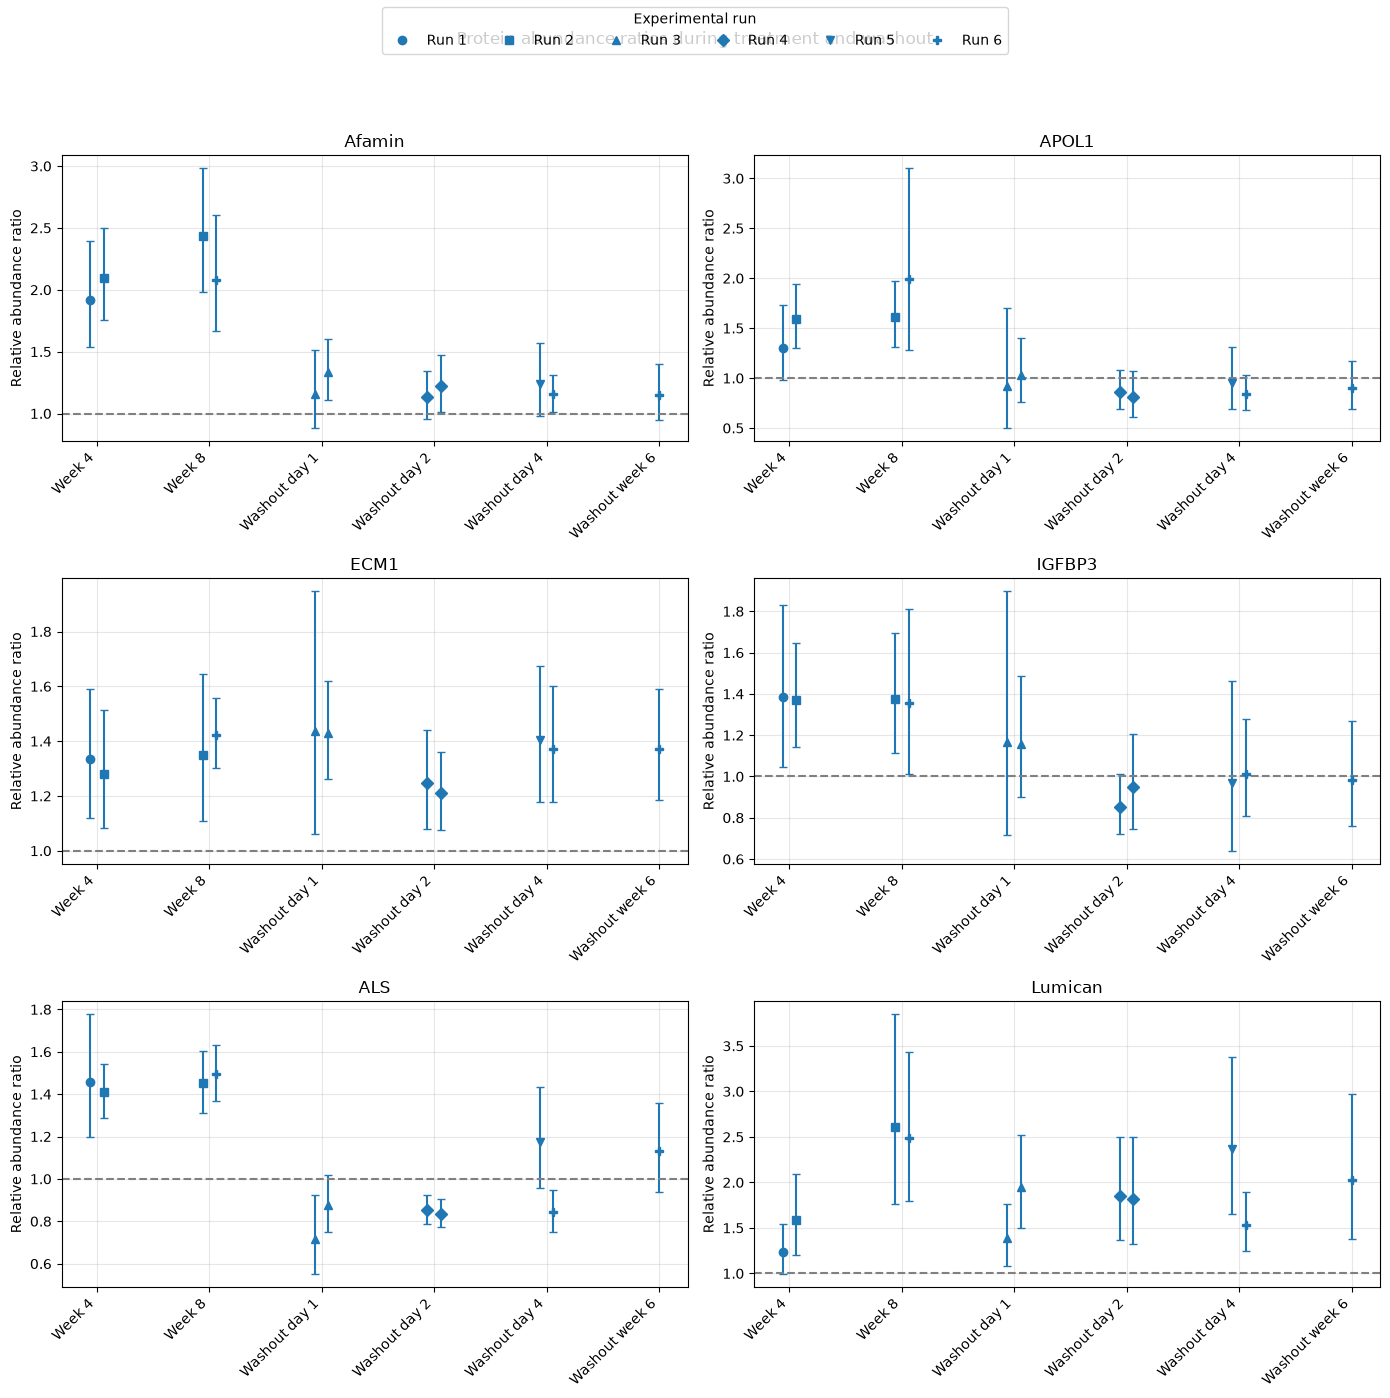

In [6]:
proteins = ["Afamin", "APOL1", "ECM1", "IGFBP3", "ALS", "Lumican"]

time_order = [
    "Week 4", "Week 8", "Washout day 1",
    "Washout day 2", "Washout day 4", "Washout week 6"
]

run_markers = {1: "o", 2: "s", 3: "^", 4: "D", 5: "v", 6: "P"}

fig, axes = plt.subplots(3, 2, figsize=(14, 14))

for ax, protein in zip(axes.flatten(), proteins):
    subset = protein_results[
        protein_results["Protein"] == protein
    ].copy()

    subset["Position"] = subset.groupby(
        "Collection time", observed=True
    ).cumcount()

    subset["N"] = subset.groupby(
        "Collection time", observed=True
    )["Ratio"].transform("count")

    subset["Offset"] = (
        subset["Position"] - (subset["N"] - 1) / 2
    ) * 0.12

    subset["X"] = [
        time_order.index(t) + offset
        for t, offset in zip(subset["Collection time"], subset["Offset"])
    ]

    for run in sorted(subset["Run"].unique()):
        run_data = subset[subset["Run"] == run]
        lower_error = run_data["Ratio"] - run_data["Lower CI"]
        upper_error = run_data["Upper CI"] - run_data["Ratio"]

        ax.errorbar(
            run_data["X"], run_data["Ratio"],
            yerr=[lower_error, upper_error],
            fmt=run_markers[run], color="C0", capsize=3
        )

    ax.axhline(1, linestyle="--", color="gray")
    ax.set_title(protein)
    ax.set_xticks(range(len(time_order)))
    ax.set_xticklabels(time_order, rotation=45, ha="right")
    ax.set_ylabel("Relative abundance ratio")
    ax.grid(True, alpha=0.3)

legend_handles = [
    Line2D([0], [0], marker=run_markers[run], color="C0",
           linestyle="None", label=f"Run {run}")
    for run in sorted(run_markers)
]

fig.legend(handles=legend_handles, loc="upper center", ncol=6,
           title="Experimental run")
fig.suptitle("Protein abundance ratios during treatment and washout")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

The plot shows that all six proteins had mean ratios above 1 during treatment. Their patterns during washout were different. For example, Lumican remained elevated at washout week 6, while APOL1 and IGFBP3 were closer to baseline.

This exploration showed that the proteins do not all follow the same pattern, so I decided to look at them together using PCA.

## 5. Course method: PCA

I used principal component analysis (PCA) to look at the six protein ratios together and see whether there were patterns among the analytical channels.

I used autoscaling because the proteins have different amounts of variation. This puts the variables on a similar scale before PCA.

In [7]:
# Put the six protein ratios into one table.
protein_wide = protein_results.pivot(
    index=["Time point", "Collection time", "Run", "Column index"],
    columns="Protein",
    values="Ratio"
).reset_index()
print(protein_wide.head())
proteins = ["Afamin", "APOL1", "ECM1", "IGFBP3", "ALS", "Lumican"]

# Autoscale the protein ratios and run PCA.
X_scaled = StandardScaler().fit_transform(protein_wide[proteins])

pca = PCA(n_components=2)
scores = pca.fit_transform(X_scaled)

pca_scores = protein_wide[
    ["Collection time", "Run", "Column index"]
].copy()
pca_scores["PC1"] = scores[:, 0]
pca_scores["PC2"] = scores[:, 1]

print("PC1:", round(pca.explained_variance_ratio_[0] * 100, 2), "%")
print("PC2:", round(pca.explained_variance_ratio_[1] * 100, 2), "%")
print("PC1 + PC2:",
      round(pca.explained_variance_ratio_[:2].sum() * 100, 2), "%")

Protein Time point Collection time  Run  Column index       ALS     APOL1  \
0             TTP1          Week 4    1            44  1.458519  1.304719   
1             TTP1          Week 4    2            49  1.410084  1.590400   
2             TTP2          Week 8    2            54  1.450467  1.608635   
3             TTP2          Week 8    6            59  1.494792  1.992962   
4             TTP3   Washout day 1    3            64  0.714975  0.924278   

Protein    Afamin      ECM1    IGFBP3   Lumican  
0        1.919845  1.333550  1.383685  1.239750  
1        2.096570  1.279760  1.369748  1.585376  
2        2.431636  1.350564  1.374575  2.605143  
3        2.082453  1.423669  1.354608  2.484351  
4        1.157629  1.437866  1.165273  1.384541  
PC1: 61.7 %
PC2: 18.44 %
PC1 + PC2: 80.14 %


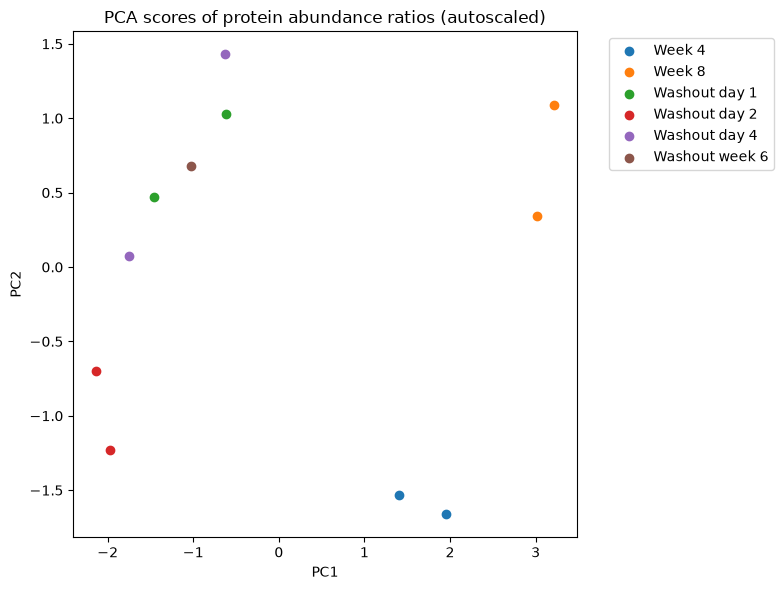

In [8]:
# Plot the PCA scores.
plt.figure(figsize=(8, 6))

for time in protein_wide["Collection time"].drop_duplicates():
    subset = pca_scores[pca_scores["Collection time"] == time]
    plt.scatter(subset["PC1"], subset["PC2"], label=time)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA scores of protein abundance ratios (autoscaled)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

PC1 explained 61.70% of the variance and PC2 explained 18.44%. Together, they explained 80.14% of the variance.

There are only 11 analytical channels, and the samples are pooled. I will use PCA as an exploratory method. One thing to check next is whether any single channel has a strong influence on the scores.

## 6. Preliminary conclusion

The six proteins showed different abundance patterns during treatment and washout. The descriptive analysis and PCA give an initial overview of these patterns.

The main limitation is that the samples were pooled, so the data cannot show individual participant responses.

## Software environment

These are the Python and package versions used to run this notebook.

In [9]:
print(f"Python       {sys.version.split()[0]}")
print(f"NumPy        {np.__version__}")
print(f"pandas       {pd.__version__}")
print(f"SciPy        {scipy.__version__}")
print(f"Matplotlib   {matplotlib.__version__}")
print(f"scikit-learn {sklearn.__version__}")

Python       3.14.7
NumPy        2.5.3
pandas       3.0.6
SciPy        1.18.1
Matplotlib   3.11.2
scikit-learn 1.9.1
